In [1]:
import requests, pandas as pd
r = requests.get("https://api.openf1.org/v1/sessions?year=2024&session_name=Race")
df = pd.DataFrame(r.json())
df.head()

,session_key,session_type,session_name,date_start,date_end,meeting_key,circuit_key,circuit_short_name,country_key,country_code,country_name,location,gmt_offset,year,is_cancelled
0,9472,Race,Race,2024-03-02T15:00:00+00:00,2024-03-02T17:00:00+00:00,1229,63,Sakhir,36,BRN,Bahrain,Sakhir,03:00:00,2024,False
1,9480,Race,Race,2024-03-09T17:00:00+00:00,2024-03-09T19:00:00+00:00,1230,149,Jeddah,153,KSA,Saudi Arabia,Jeddah,03:00:00,2024,False
2,9488,Race,Race,2024-03-24T04:00:00+00:00,2024-03-24T06:00:00+00:00,1231,10,Melbourne,5,AUS,Australia,Melbourne,11:00:00,2024,False
3,9496,Race,Race,2024-04-07T05:00:00+00:00,2024-04-07T07:00:00+00:00,1232,46,Suzuka,4,JPN,Japan,Suzuka,09:00:00,2024,False
4,9673,Race,Race,2024-04-21T07:00:00+00:00,2024-04-21T09:00:00+00:00,1233,49,Shanghai,53,CHN,China,Shanghai,08:00:00,2024,False


In [2]:
df.columns            # all the column names
len(df)               # how many races
df[["country_name", "circuit_short_name", "date_start", "session_key"]]

,country_name,circuit_short_name,date_start,session_key
0,Bahrain,Sakhir,2024-03-02T15:00:00+00:00,9472
1,Saudi Arabia,Jeddah,2024-03-09T17:00:00+00:00,9480
2,Australia,Melbourne,2024-03-24T04:00:00+00:00,9488
3,Japan,Suzuka,2024-04-07T05:00:00+00:00,9496
4,China,Shanghai,2024-04-21T07:00:00+00:00,9673
5,United States,Miami,2024-05-05T20:00:00+00:00,9507
6,Italy,Imola,2024-05-19T13:00:00+00:00,9515
7,Monaco,Monte Carlo,2024-05-26T13:00:00+00:00,9523
8,Canada,Montreal,2024-06-09T18:00:00+00:00,9531
9,Spain,Catalunya,2024-06-23T13:00:00+00:00,9539


In [3]:
italy = df[df["country_name"] == "Italy"]
italy

italy[["circuit_short_name", "date_start", "session_key"]]

key = italy["session_key"].iloc[0]
key



np.int64(9515)

In [4]:
from f1.fetch import get_cached, top_drivers
top = top_drivers(2025)
top

,position_current,driver_number,full_name,team_name,points_current
0,1,4,Lando NORRIS,McLaren,423.0
1,2,1,Max VERSTAPPEN,Red Bull Racing,421.0
2,3,81,Oscar PIASTRI,McLaren,410.0
3,4,63,George RUSSELL,Mercedes,319.0
4,5,16,Charles LECLERC,Ferrari,242.0


[0 0 0 0 0]
322
115.2189167382421
4 (38421, 10)
1 (38421, 10)
81 (38421, 10)
63 (38421, 10)
16 (38421, 10)


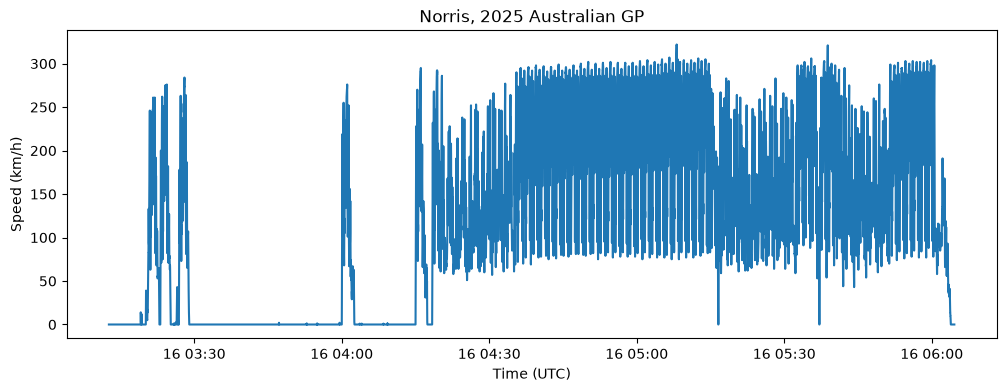

,lap_number,date_start,lap_duration
0,1,2025-03-16 04:18:22.973000+00:00,117.430
1,2,2025-03-16 04:20:20.402000+00:00,169.888
2,3,2025-03-16 04:23:10.339000+00:00,161.723
3,4,2025-03-16 04:25:52.068000+00:00,156.053
4,5,2025-03-16 04:28:28.177000+00:00,143.648


In [5]:
from f1.fetch import get_cached, top_drivers

top = top_drivers(2025)
numbers = top["driver_number"].tolist()
numbers

tel = get_cached("aus2025_car_4", "car_data", session_key=9693, driver_number=4)
tel.shape
tel.head()

speed = tel["speed"].to_numpy()
speed[:5]
speed.max()
speed.mean()

print(speed[:5])
print(speed.max())
print(speed.mean())

telemetry = {}                      # empty dictionary: driver number -> table

for num in numbers:
    telemetry[num] = get_cached(f"aus2025_car_{num}", "car_data",
                                session_key=9693, driver_number=num)
    print(num, telemetry[num].shape)

import matplotlib.pyplot as plt
import pandas as pd

t = telemetry[4]
time = pd.to_datetime(t["date"], format="ISO8601")      # turn the text dates into real timestamps
speed = t["speed"].to_numpy()

plt.figure(figsize=(12, 4))
plt.plot(time, speed)
plt.xlabel("Time (UTC)")
plt.ylabel("Speed (km/h)")
plt.title("Norris, 2025 Australian GP")
plt.show()

laps = get_cached("aus2025_laps", "laps", session_key=9693, driver_number=4)

laps["date_start"] = pd.to_datetime(laps["date_start"], format="ISO8601")
laps[["lap_number", "date_start", "lap_duration"]].head()

In [6]:
from f1.fetch import endpoint_reference

# quick lookup table: every OpenF1 endpoint, how often rows show up, and its key fields
ref = endpoint_reference()
pd.set_option("display.max_colwidth", None)
ref

,endpoint,granularity,key_fields
0,sessions,1 row per session (practice/quali/race),"session_name, session_type, date_start/end, circuit_short_name, year"
1,meetings,1 row per Grand Prix weekend,"meeting_name, country_name, circuit_key, year"
2,drivers,1 row per driver per session,"full_name, name_acronym, team_name, team_colour, headshot_url"
3,laps,1 row per driver per lap,"lap_number, lap_duration, duration_sector_1/2/3, i1_speed, i2_speed, st_speed, is_pit_out_lap"
4,car_data,~3.7 Hz telemetry samples,"speed, throttle, brake, n_gear, rpm, drs"
5,location,~3.7 Hz,"x, y, z (track-position coordinates)"
6,position,1 row per position change,"position, date"
7,intervals,"~every 4s, race only","gap_to_leader, interval (gap to car ahead)"
8,stints,1 row per tyre stint,"compound, lap_start, lap_end, tyre_age_at_start"
9,pit,1 row per pit stop,"lap_number, lane_duration, stop_duration"
